# Phase 1: Baseline quantization & benchmarking (llama.cpp on Kaggle)

**Goal:** build the measurement foundation for the auto-optimizer. For one small model we produce standard quantizations (F16, Q8_0 ... Q2_K) and measure quality (perplexity), speed (prompt + generation tokens/s on GPU and CPU) and memory (file size, peak GPU memory, peak RAM).

**Before running**
1. Settings -> Accelerator: **GPU T4 x2** or **GPU P100**
2. Settings -> Internet: **On** (needs a phone-verified account)
3. For unattended runs use **Save & Run All (Commit)**

**Pipeline:** build llama.cpp (CUDA) -> download HF model -> convert to F16 GGUF -> quantize -> perplexity on WikiText-2 -> `llama-bench` on GPU and CPU-only -> table + plots.

Results are appended to a JSONL file after every quant type, so a crashed run resumes where it stopped (re-attach the previous run's output as an input dataset and copy `results/*.jsonl` back into `/kaggle/working/results`).

In [1]:
import os, json, re, time, subprocess, pathlib, tempfile

# Benchmark on ONE GPU even if Kaggle gives T4 x2, so numbers are comparable
os.environ["CUDA_VISIBLE_DEVICES"] = "0"

MODEL_ID    = "Qwen/Qwen2.5-1.5B"   # base model; swap for another small model if you like
MODEL_NAME  = MODEL_ID.split("/")[-1]
QUANT_TYPES = ["Q8_0", "Q6_K", "Q5_K_M", "Q4_K_M", "Q3_K_M", "Q2_K"]

PPL_CHUNKS  = 100                   # 512-token chunks of WikiText-2 test; None = full set
BENCH_PP, BENCH_TG, BENCH_REPS = 512, 128, 3
CPU_THREADS = os.cpu_count()

WORK    = pathlib.Path("/kaggle/working")
LLAMA   = WORK / "llama.cpp"
BIN     = LLAMA / "build" / "bin"
MODELS  = WORK / "models"
RESULTS = WORK / "results"
for d in (MODELS, RESULTS):
    d.mkdir(parents=True, exist_ok=True)

def sh(cmd, check=True):
    print("$", cmd)
    r = subprocess.run(cmd, shell=True, text=True, capture_output=True)
    if check and r.returncode != 0:
        print(r.stdout[-3000:], r.stderr[-3000:])
        raise RuntimeError("command failed: " + cmd)
    return (r.stdout + r.stderr).strip()

print(sh("nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv"))
print(sh("lscpu | grep -E 'Model name|^CPU\\(s\\)'", check=False))
print(sh("free -h | head -2"))

$ nvidia-smi --query-gpu=name,memory.total,compute_cap --format=csv
name, memory.total [MiB], compute_cap
Tesla T4, 15360 MiB, 7.5
Tesla T4, 15360 MiB, 7.5
$ lscpu | grep -E 'Model name|^CPU\(s\)'
CPU(s):                                  4
Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz
$ free -h | head -2
total        used        free      shared  buff/cache   available
Mem:            31Gi       1.2Gi        25Gi       1.2Mi       5.1Gi        30Gi


## 1. Build llama.cpp with CUDA
Takes roughly 5-10 minutes on a fresh session. Only the four tools we need are built.

In [2]:
import shutil
arch = 75   # T4; use 60 if you got a P100

if not (BIN / "llama-quantize").exists():
    if not LLAMA.exists():
        sh(f"git clone --depth 1 https://github.com/ggml-org/llama.cpp {LLAMA}")
    shutil.rmtree(LLAMA / "build", ignore_errors=True)
    if not shutil.which("nvcc") and os.path.exists("/usr/local/cuda/bin/nvcc"):
        os.environ["PATH"] += ":/usr/local/cuda/bin"

    cfg = (f"cmake -S {LLAMA} -B {LLAMA/'build'} -DGGML_CUDA=ON "
           f"-DCMAKE_CUDA_ARCHITECTURES={arch} -DGGML_CUDA_NO_VMM=ON "
           f"-DLLAMA_CURL=OFF -DCMAKE_BUILD_TYPE=Release")
    r = subprocess.run(cfg, shell=True, text=True, capture_output=True)
    if r.returncode != 0:
        print((r.stdout + r.stderr)[:4000])
        raise RuntimeError("cmake configure failed")
    sh(f"cmake --build {LLAMA/'build'} --config Release -j {os.cpu_count()} "
       f"--target llama-quantize llama-bench llama-perplexity llama-cli")

LLAMA_COMMIT = sh(f"git -C {LLAMA} rev-parse --short HEAD", check=False)
print("llama.cpp commit:", LLAMA_COMMIT)

$ git clone --depth 1 https://github.com/ggml-org/llama.cpp /kaggle/working/llama.cpp
$ cmake --build /kaggle/working/llama.cpp/build --config Release -j 4 --target llama-quantize llama-bench llama-perplexity llama-cli
$ git -C /kaggle/working/llama.cpp rev-parse --short HEAD
llama.cpp commit: 1537a0a


## 2. Download the model and convert to F16 GGUF

In [3]:
sh(f"pip install -q {LLAMA/'gguf-py'} sentencepiece")

from huggingface_hub import snapshot_download
hf_dir = snapshot_download(
    MODEL_ID,
    local_dir=str(WORK / "hf" / MODEL_NAME),
    allow_patterns=["*.json", "*.safetensors", "*.model", "*.txt", "tokenizer*"],
)

F16 = MODELS / f"{MODEL_NAME}-F16.gguf"
if not F16.exists():
    sh(f"python {LLAMA/'convert_hf_to_gguf.py'} {hf_dir} --outfile {F16} --outtype f16")
print(F16.name, f"{F16.stat().st_size/1e6:.0f} MB")

$ pip install -q /kaggle/working/llama.cpp/gguf-py sentencepiece


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 7 files:   0%|          | 0/7 [00:00<?, ?it/s]

$ python /kaggle/working/llama.cpp/convert_hf_to_gguf.py /kaggle/working/hf/Qwen2.5-1.5B --outfile /kaggle/working/models/Qwen2.5-1.5B-F16.gguf --outtype f16
Qwen2.5-1.5B-F16.gguf 3094 MB


## 3. Quantize

In [4]:
quants = {"F16": F16}
for q in QUANT_TYPES:
    out = MODELS / f"{MODEL_NAME}-{q}.gguf"
    if not out.exists():
        t = time.time()
        sh(f"{BIN/'llama-quantize'} {F16} {out} {q}")
        print(f"{q:8s} {out.stat().st_size/1e6:7.0f} MB  ({time.time()-t:.0f}s)")
    quants[q] = out

$ /kaggle/working/llama.cpp/build/bin/llama-quantize /kaggle/working/models/Qwen2.5-1.5B-F16.gguf /kaggle/working/models/Qwen2.5-1.5B-Q8_0.gguf Q8_0
Q8_0        1647 MB  (21s)
$ /kaggle/working/llama.cpp/build/bin/llama-quantize /kaggle/working/models/Qwen2.5-1.5B-F16.gguf /kaggle/working/models/Qwen2.5-1.5B-Q6_K.gguf Q6_K
Q6_K        1273 MB  (39s)
$ /kaggle/working/llama.cpp/build/bin/llama-quantize /kaggle/working/models/Qwen2.5-1.5B-F16.gguf /kaggle/working/models/Qwen2.5-1.5B-Q5_K_M.gguf Q5_K_M
Q5_K_M      1125 MB  (64s)
$ /kaggle/working/llama.cpp/build/bin/llama-quantize /kaggle/working/models/Qwen2.5-1.5B-F16.gguf /kaggle/working/models/Qwen2.5-1.5B-Q4_K_M.gguf Q4_K_M
Q4_K_M       986 MB  (76s)
$ /kaggle/working/llama.cpp/build/bin/llama-quantize /kaggle/working/models/Qwen2.5-1.5B-F16.gguf /kaggle/working/models/Qwen2.5-1.5B-Q3_K_M.gguf Q3_K_M
Q3_K_M       824 MB  (43s)
$ /kaggle/working/llama.cpp/build/bin/llama-quantize /kaggle/working/models/Qwen2.5-1.5B-F16.gguf /kaggle/wo

## 4. Evaluation data (WikiText-2 test, raw)

In [5]:
WIKI = WORK / "wiki.test.raw"
if not WIKI.exists():
    try:
        from datasets import load_dataset
        ds = load_dataset("Salesforce/wikitext", "wikitext-2-raw-v1", split="test")
        text = "".join(ds["text"])
    except Exception as e:
        print("datasets route failed, downloading the parquet file directly:", repr(e)[:200])
        import pandas as pd
        from huggingface_hub import hf_hub_download
        p = hf_hub_download("Salesforce/wikitext", "wikitext-2-raw-v1/test-00000-of-00001.parquet",
                            repo_type="dataset")
        text = "".join(pd.read_parquet(p)["text"])
    WIKI.write_text(text)
print(f"{WIKI.stat().st_size/1e6:.1f} MB of eval text")

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

datasets route failed, downloading the parquet file directly: ImportError("cannot import name '_slice' from 'numpy._core.umath' (/usr/local/lib/python3.13/dist-packages/numpy/_core/umath.py)")


wikitext-2-raw-v1/test-00000-of-00001.pa(…): reconstructing file:   0%|          |  0.00B /  733kB            

wikitext-2-raw-v1/test-00000-of-00001.pa(…): downloading bytes:           |  0.00B            

1.3 MB of eval text


## 5. Measurement harness
- `run_monitored` runs a command while sampling peak **GPU memory** (nvidia-smi) and peak **process RAM** (psutil).
- `bench` wraps `llama-bench`. The CPU run hides the GPU (`CUDA_VISIBLE_DEVICES=""`) so it is a true CPU-only number, our proxy for an edge device.
- `perplexity` wraps `llama-perplexity` (device-independent, so run once on GPU).

In [6]:
import psutil

def gpu_mem_mb():
    out = subprocess.run("nvidia-smi -i 0 --query-gpu=memory.used --format=csv,noheader,nounits",
                         shell=True, capture_output=True, text=True).stdout
    return float(out.strip().splitlines()[0])

def run_monitored(cmd, env=None):
    # returns (stdout, stderr, peak_gpu_mb, peak_rss_mb, returncode)
    base_gpu = gpu_mem_mb()
    with tempfile.TemporaryFile("w+") as fo, tempfile.TemporaryFile("w+") as fe:
        p = subprocess.Popen(cmd, stdout=fo, stderr=fe, text=True, env=env)
        ps = psutil.Process(p.pid)
        peak_gpu, peak_rss = 0.0, 0.0
        while p.poll() is None:
            try:
                peak_gpu = max(peak_gpu, gpu_mem_mb() - base_gpu)
                procs = [ps] + ps.children(recursive=True)
                peak_rss = max(peak_rss, sum(c.memory_info().rss for c in procs) / 1e6)
            except (psutil.Error, ValueError):
                pass
            time.sleep(0.25)
        fo.seek(0); fe.seek(0)
        return fo.read(), fe.read(), peak_gpu, peak_rss, p.returncode

def bench(model_path, ngl, cpu_only=False):
    cmd = [str(BIN / "llama-bench"), "-m", str(model_path),
           "-p", str(BENCH_PP), "-n", str(BENCH_TG), "-r", str(BENCH_REPS),
           "-ngl", str(ngl), "-t", str(CPU_THREADS), "-o", "json"]
    env = {**os.environ, "CUDA_VISIBLE_DEVICES": ""} if cpu_only else None
    out, err, gpu, rss, rc = run_monitored(cmd, env)
    if rc != 0:
        raise RuntimeError(err[-2000:])
    rows = json.loads(out[out.index("["):])
    pp = next(r for r in rows if r["n_prompt"] > 0 and r["n_gen"] == 0)
    tg = next(r for r in rows if r["n_gen"] > 0 and r["n_prompt"] == 0)
    return {"pp_tps": pp["avg_ts"], "pp_std": pp["stddev_ts"],
            "tg_tps": tg["avg_ts"], "tg_std": tg["stddev_ts"],
            "peak_gpu_mb": gpu, "peak_rss_mb": rss}

def perplexity(model_path):
    cmd = [str(BIN / "llama-perplexity"), "-m", str(model_path), "-f", str(WIKI),
           "-ngl", "99", "-c", "512"]
    if PPL_CHUNKS:
        cmd += ["--chunks", str(PPL_CHUNKS)]
    out, err, _, _, rc = run_monitored(cmd)
    m = re.search(r"Final estimate: PPL = ([\d.]+) \+/- ([\d.]+)", out + err)
    if rc != 0 or not m:
        raise RuntimeError((out + err)[-2000:])
    return float(m.group(1)), float(m.group(2))

# quick smoke test on the smallest model before the full sweep
smoke = bench(quants[QUANT_TYPES[-1]], 99)
print({k: round(v, 1) for k, v in smoke.items()})

{'pp_tps': 3646.1, 'pp_std': 419.9, 'tg_tps': 148.5, 'tg_std': 0.3, 'peak_gpu_mb': 1089.0, 'peak_rss_mb': 1010.2}


## 6. Run the baseline sweep
One record per quant type is appended to a JSONL file as soon as it finishes (resumable).

In [7]:
RESULTS_FILE = RESULTS / f"phase1_{MODEL_NAME}.jsonl"
records = {}
if RESULTS_FILE.exists():
    for line in RESULTS_FILE.read_text().splitlines():
        r = json.loads(line)
        records[r["quant"]] = r

for name, path in quants.items():
    if name in records:
        print("skip (already done):", name)
        continue
    t = time.time()
    print("==", name)
    rec = {"quant": name, "size_mb": path.stat().st_size / 1e6}
    rec["ppl"], rec["ppl_err"] = perplexity(path)
    rec.update({"gpu_" + k: v for k, v in bench(path, 99).items()})
    rec.update({"cpu_" + k: v for k, v in bench(path, 0, cpu_only=True).items()})
    records[name] = rec
    with open(RESULTS_FILE, "a") as f:
        f.write(json.dumps(rec) + "\n")
    print(f"   ppl={rec['ppl']:.3f}  gpu_tg={rec['gpu_tg_tps']:.1f} t/s  "
          f"cpu_tg={rec['cpu_tg_tps']:.1f} t/s  ({time.time()-t:.0f}s)")

== F16
   ppl=9.681  gpu_tg=67.2 t/s  cpu_tg=6.9 t/s  (127s)
== Q8_0
   ppl=9.702  gpu_tg=108.3 t/s  cpu_tg=10.5 t/s  (135s)
== Q6_K
   ppl=9.759  gpu_tg=117.3 t/s  cpu_tg=12.8 t/s  (114s)
== Q5_K_M
   ppl=9.801  gpu_tg=134.8 t/s  cpu_tg=12.0 t/s  (117s)
== Q4_K_M
   ppl=10.042  gpu_tg=144.3 t/s  cpu_tg=14.8 t/s  (94s)
== Q3_K_M
   ppl=11.310  gpu_tg=126.5 t/s  cpu_tg=13.3 t/s  (106s)
== Q2_K
   ppl=22.722  gpu_tg=138.6 t/s  cpu_tg=15.5 t/s  (104s)


## 7. Results table and plots

,quant,size_mb,ppl,ppl_delta_pct,gpu_pp_tps,gpu_tg_tps,cpu_pp_tps,cpu_tg_tps,gpu_peak_gpu_mb,cpu_peak_rss_mb
0,F16,3093.67,9.68,0.00,6144.37,67.17,55.76,6.90,3409.0,3405.79
1,Q8_0,1646.57,9.70,0.22,4845.19,108.26,31.48,10.55,2013.0,1954.35
2,Q6_K,1272.74,9.76,0.81,4538.76,117.34,41.15,12.80,1657.0,1582.61
3,Q5_K_M,1125.05,9.80,1.24,4749.80,134.82,40.10,11.97,1515.0,1434.94
4,Q4_K_M,986.05,10.04,3.72,4846.88,144.29,59.94,14.81,1383.0,1913.79
5,Q3_K_M,824.18,11.31,16.83,4417.36,126.50,48.70,13.26,1229.0,1385.82
6,Q2_K,676.30,22.72,134.71,3634.35,138.61,48.86,15.46,1089.0,1266.19


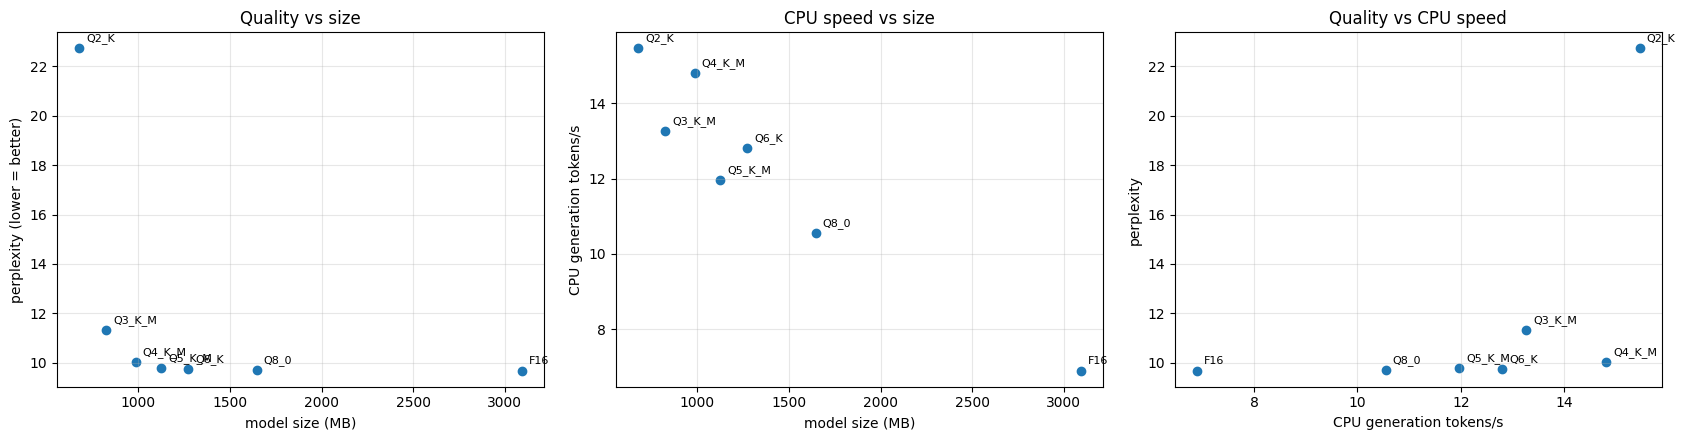

In [8]:
import pandas as pd
import matplotlib.pyplot as plt

df = pd.DataFrame(records.values())
base_ppl = df.loc[df.quant == "F16", "ppl"].iloc[0]
df["ppl_delta_pct"] = (df.ppl / base_ppl - 1) * 100
df = df.sort_values("size_mb", ascending=False).reset_index(drop=True)

cols = ["quant", "size_mb", "ppl", "ppl_delta_pct", "gpu_pp_tps", "gpu_tg_tps",
        "cpu_pp_tps", "cpu_tg_tps", "peak_gpu_mb" if "peak_gpu_mb" in df else "gpu_peak_gpu_mb",
        "cpu_peak_rss_mb"]
cols = [c for c in cols if c in df.columns]
display(df[cols].round(2))

fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))
def scatter(a, x, y, xl, yl, title):
    a.scatter(df[x], df[y])
    for _, r in df.iterrows():
        a.annotate(r.quant, (r[x], r[y]), textcoords="offset points", xytext=(5, 5), fontsize=8)
    a.set_xlabel(xl); a.set_ylabel(yl); a.set_title(title); a.grid(alpha=.3)

scatter(ax[0], "size_mb", "ppl", "model size (MB)", "perplexity (lower = better)", "Quality vs size")
scatter(ax[1], "size_mb", "cpu_tg_tps", "model size (MB)", "CPU generation tokens/s", "CPU speed vs size")
scatter(ax[2], "cpu_tg_tps", "ppl", "CPU generation tokens/s", "perplexity", "Quality vs CPU speed")
plt.tight_layout()
plt.savefig(RESULTS / f"phase1_{MODEL_NAME}.png", dpi=150)
plt.show()

## 8. Save run metadata
Record the environment next to the results so every number can be reproduced and compared later.

In [9]:
LLAMA_COMMIT = sh(f"git -C {LLAMA} rev-parse --short HEAD", check=False)
meta = {
    "model": MODEL_ID,
    "llama_cpp_commit": LLAMA_COMMIT,
    "gpu": sh("nvidia-smi -i 0 --query-gpu=name --format=csv,noheader", check=False),
    "cpu": sh("lscpu | grep 'Model name'", check=False),
    "cpu_threads": CPU_THREADS,
    "ppl_chunks": PPL_CHUNKS,
    "bench": {"pp": BENCH_PP, "tg": BENCH_TG, "reps": BENCH_REPS},
    "date": time.strftime("%Y-%m-%d %H:%M"),
}
(RESULTS / f"phase1_{MODEL_NAME}_meta.json").write_text(json.dumps(meta, indent=2))
df.to_csv(RESULTS / f"phase1_{MODEL_NAME}.csv", index=False)
print(json.dumps(meta, indent=2))

$ git -C /kaggle/working/llama.cpp rev-parse --short HEAD
$ nvidia-smi -i 0 --query-gpu=name --format=csv,noheader
$ lscpu | grep 'Model name'
{
  "model": "Qwen/Qwen2.5-1.5B",
  "llama_cpp_commit": "1537a0a",
  "gpu": "Tesla T4",
  "cpu": "Model name:                              Intel(R) Xeon(R) CPU @ 2.00GHz",
  "cpu_threads": 4,
  "ppl_chunks": 100,
  "bench": {
    "pp": 512,
    "tg": 128,
    "reps": 3
  },
  "date": "2026-10-03 17:55"
}


## What this gives you for the next phase
- A **baseline table** (F16 + standard presets) to compare your automated search against.
- A tested **profiler** (`bench`, `perplexity`, `run_monitored`) that Phase 2 (per-layer sensitivity) and Phase 3 (the search) will call.
- Next: per-layer sensitivity analysis. Quantize one block at a time to a low bit width and record the perplexity change.